# Cycle 5 - Modèle final : évaluation sur le test et interprétation

Objectifs de ce cycle :
1. Entraîner la Random Forest avec les hyperparamètres retenus au cycle 4.
2. L'évaluer **une seule fois** sur le jeu de test (2009 à 2013), jamais utilisé jusqu'ici, et la comparer à la baseline naïve sur ces mêmes années.
3. Interpréter le modèle : erreur par culture et variables importantes.

In [2]:
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

import notebooks.utils as utils
from notebooks.agritech_feature_engineering import AgritechFeatureEngineering

In [ ]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Agriculture_optimization")

In [4]:
dataset = pd.read_csv('../data/rafined/dataset.csv', sep=',')
dataset.drop(columns=['Area ISO Code', 'Area ISO Alpha-2 Code', 'Area ISO Alpha-3 Code'], inplace=True)

## Données d'entrée du modèle

Le modèle n'utilise que les colonnes ci-dessous : ce sont exactement celles que l'API devra lui fournir. Les valeurs climatiques ou de pesticides peuvent être manquantes (`NaN`) : le pipeline les remplace par la médiane, et les indicateurs `missing_*` signalent qu'elles étaient absentes.

In [5]:
RANDOM_STATE = 42
TARGET = 'hg/ha'

CATEGORICAL_FEATURES = ['Area', 'Item']
NUMERIC_INPUTS = [
    'avg_temp',
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'pesticides_kg_ha',
    'missing_pesticide_value',
    'missing_rain_value',
    'missing_temp_value',
]
INPUT_FEATURES = CATEGORICAL_FEATURES + NUMERIC_INPUTS

X_train, X_test, y_train, y_test = utils.test_train_time_split(dataset)
X_train = X_train.sort_values('Year')
y_train = y_train.loc[X_train.index]
split_year = int(X_test['Year'].min())

X_train, X_test = X_train[INPUT_FEATURES], X_test[INPUT_FEATURES]

Année de césure calculée : 2009
Proportion réelle train : 78.73% (20349 lignes)
Proportion réelle test  : 21.27% (5499 lignes)


## Modèle final

Random Forest avec les hyperparamètres gagnants du cycle 4 (run MLflow « Cycle 4 - Optimisation Random Forest (RandomizedSearchCV) »), cible transformée en `log1p`, même prétraitement que dans les cycles précédents.

In [6]:
# Hyperparamètres retenus au cycle 4 (RandomizedSearchCV, meilleure RMSE en validation croisée temporelle)
BEST_PARAMS = {
    'n_estimators': 200,
    'max_features': 0.5,
    'max_depth': 40,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'bootstrap': False,
}


def build_model():
    """Construit le pipeline complet : feature engineering, prétraitement, Random Forest sur cible log1p."""
    numeric_features = NUMERIC_INPUTS + ['aridity', 'avg_temp_square']  # 2 variables créées par AgritechFeatureEngineering

    preprocessor = ColumnTransformer(
        transformers=[
            ('area_encoding',
             TargetEncoder(target_type='continuous', cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)),
             ['Area']),
            ('item_encoding', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Item']),
            ('num_pipeline', Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
            ]), numeric_features),
        ],
        remainder='drop'
    )

    pipeline = Pipeline([
        ('features', AgritechFeatureEngineering()),
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(**BEST_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)),
    ])

    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)

## Évaluation finale sur le jeu de test (2009 à 2013)

Le modèle est entraîné sur 1990 à 2008, puis évalué une seule fois sur 2009 à 2013. La baseline naïve (médiane pays × culture) est recalculée sur exactement les mêmes années, ce qui rend la comparaison directe.

In [23]:
# Modèle entraîné sur le passé (1990-2008) uniquement
eval_model = build_model().fit(X_train, y_train)
pred_test = eval_model.predict(X_test)

test_metrics = utils.evaluate(y_test, pred_test)

# Baseline naïve sur les mêmes années : médiane historique du couple (pays, culture)
train_df = X_train.assign(**{TARGET: y_train})
mediane_pays_culture = train_df.groupby(['Area', 'Item'])[TARGET].median()
mediane_culture = train_df.groupby('Item')[TARGET].median()
pred_baseline = X_test.join(mediane_pays_culture.rename('pred'), on=['Area', 'Item'])['pred']
pred_baseline = pred_baseline.fillna(X_test['Item'].map(mediane_culture))

baseline_metrics = utils.evaluate(y_test, pred_baseline)

comparaison_test = pd.DataFrame({'Baseline naïve': baseline_metrics, 'Random Forest optimisée': test_metrics}).T[['r2', 'mae', 'rmse']]
comparaison_test.round(3)

,r2,mae,rmse
Baseline naïve,0.836,16461.082,32645.915
Random Forest optimisée,0.852,15808.246,31012.026


In [25]:
# Erreur par culture sur le test : le modèle est-il fiable pour toutes les cultures ?
erreurs = pd.DataFrame({'Item': X_test['Item'], 'reel': y_test, 'modele': pred_test, 'baseline': pred_baseline})

par_culture = erreurs.groupby('Item').apply(lambda g: pd.Series({
    'rendement_median': g['reel'].median(),
    'mae_modele': (g['modele'] - g['reel']).abs().mean(),
    'mae_baseline': (g['baseline'] - g['reel']).abs().mean(),
}), include_groups=False)
par_culture.sort_values('rendement_median').round(2)

,rendement_median,mae_modele,mae_baseline
Item,,,
Sorgho,13565.0,6575.83,6625.87
Soja,16054.0,3480.71,3194.68
Blé,26635.5,5480.10,5829.19
Maïs,30713.0,11930.05,13059.81
Riz,36057.0,7921.92,8779.30
Igname,79388.5,18958.75,18505.72
Plantains et autres,88010.5,18436.86,20335.40
Patate douce,88404.0,25399.29,26004.27
Manioc,100000.0,23412.29,25838.92


## Variables les plus importantes

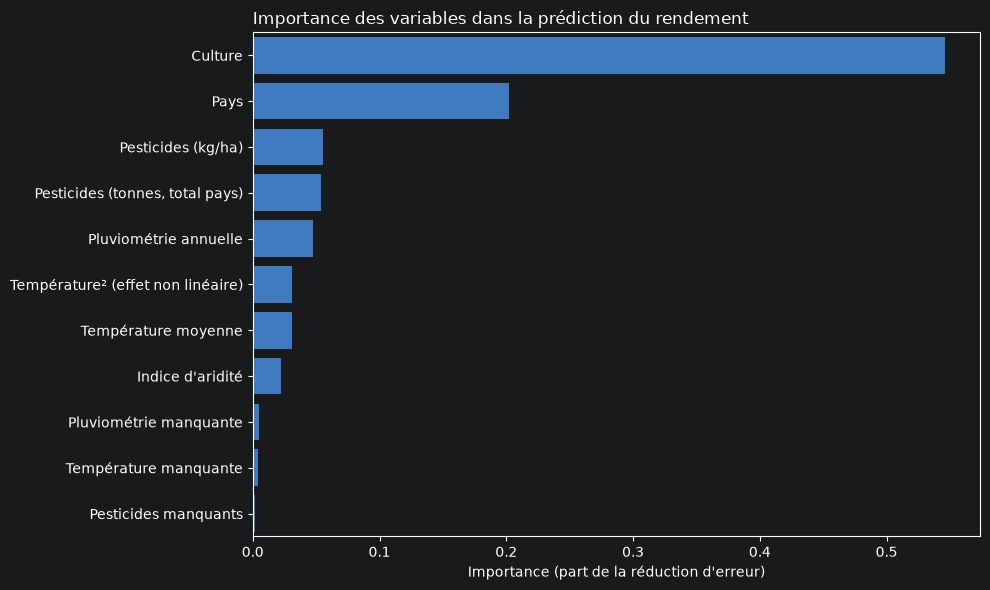

,Variable,Importance
1,Culture,0.546
0,Pays,0.202
9,Pesticides (kg/ha),0.055
10,"Pesticides (tonnes, total pays)",0.054
3,Pluviométrie annuelle,0.048
5,Température² (effet non linéaire),0.031
4,Température moyenne,0.031
2,Indice d'aridité,0.022
7,Pluviométrie manquante,0.005
8,Température manquante,0.004


In [16]:
fitted_pipeline = eval_model.regressor_
rf = fitted_pipeline.named_steps['model']
noms_variables = fitted_pipeline.named_steps['preprocessor'].get_feature_names_out()

df_importance = pd.DataFrame({'Variable': noms_variables, 'Importance': rf.feature_importances_})
df_importance['Variable'] = df_importance['Variable'].str.split('__').str[1]

# Regroupement des 10 colonnes one-hot de la culture en une seule variable
df_importance.loc[df_importance['Variable'].str.startswith('Item_'), 'Variable'] = 'Item'
df_importance = df_importance.groupby('Variable', as_index=False)['Importance'].sum()

libelles = {
    'Item': 'Culture',
    'Area': 'Pays',
    'pesticides_kg_ha': 'Pesticides (kg/ha)',
    'pesticides_tonnes': 'Pesticides (tonnes, total pays)',
    'average_rain_fall_mm_per_year': 'Pluviométrie annuelle',
    'avg_temp': 'Température moyenne',
    'avg_temp_square': 'Température² (effet non linéaire)',
    'aridity': "Indice d'aridité",
    'missing_temp_value': 'Température manquante',
    'missing_rain_value': 'Pluviométrie manquante',
    'missing_pesticide_value': 'Pesticides manquants',
}
df_importance['Variable'] = df_importance['Variable'].map(libelles).fillna(df_importance['Variable'])
df_importance = df_importance.sort_values('Importance', ascending=False)

fig_importance, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=df_importance, x='Importance', y='Variable', color='#2a78d6', ax=ax)
ax.set_title("Importance des variables dans la prédiction du rendement", loc='left')
ax.set_xlabel("Importance (part de la réduction d'erreur)")
ax.set_ylabel("")
fig_importance.tight_layout()
plt.show()

df_importance.round(3)

## Enregistrement dans MLflow

In [ ]:
with mlflow.start_run(run_name="Cycle 5 - Modèle final (évaluation test)"):
    mlflow.set_tag('cycle', '5_modele_final')
    mlflow.log_params(BEST_PARAMS)
    mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics.items()})
    mlflow.log_metrics({f'baseline_test_{k}': v for k, v in baseline_metrics.items()})
    mlflow.log_figure(fig_importance, 'importance_variables.png')
    mlflow.log_table(par_culture.reset_index(), artifact_file='erreur_par_culture.json')

## Conclusion du cycle 5

- **Sur le jeu de test (2009 à 2013), la Random Forest bat la baseline naïve, mais de peu** : R² de 0.852 contre 0.836, erreur moyenne (MAE) de 15 808 hg/ha contre 16 461 (−4 %), RMSE de 31 012 contre 32 646 (−5 %). Le modèle se trompe en moyenne d'environ 1,6 tonne par hectare.
- **Le gain est plus faible qu'en validation croisée** (environ −23 % de RMSE au cycle 4). Les années de test sont plus difficiles : le modèle n'a vu que des données d'avant 2009, alors que les rendements continuent d'augmenter.
- **Par culture**, le modèle fait mieux que la baseline pour 8 cultures sur 10, surtout le riz, le manioc, les plantains et le maïs (environ −9 % d'erreur). Il fait un peu moins bien pour le soja et l'igname.
- **Variables importantes** : la culture (55 %) et le pays (20 %) expliquent l'essentiel des prédictions. Les pesticides (11 %) et le climat (13 %) jouent un rôle plus faible, mais ce sont les seuls leviers sur lesquels un agriculteur peut agir ou qu'il peut anticiper. Attention : une importance élevée ne dit pas dans quel sens joue la variable, et elle ne prouve pas un lien de cause à effet.

Ce modèle est retenu, mais avec 200 arbres il est trop lourd pour l'hébergement visé : le cycle 6 l'allège avant de le sauvegarder pour l'API.